In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

file_path = Path("../01_Raw_Data/marketing_data.xlsx")

df = pd.read_excel(file_path)

# Sütun adlarını standartlaşdırırıq
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 28)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,...,6,1,0,0,0,0,0,1,0,Spain
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,...,7,5,0,0,0,0,1,1,0,Canada
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,...,5,2,0,0,0,0,0,0,0,USA
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,...,2,7,0,0,0,0,0,0,0,Australia
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,...,2,7,1,0,0,0,0,1,0,Spain


In [2]:
Q1 = df["Income"].quantile(0.25)
Q3 = df["Income"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 35303.0
Q3: 68522.0
IQR: 33219.0
Lower Bound: -14525.5
Upper Bound: 118350.5


In [3]:
income_outliers = df[
    (df["Income"] < lower_bound) |
    (df["Income"] > upper_bound)
]

print("Income Outlier Count:", len(income_outliers))

display(
    income_outliers[
        ["ID", "Income", "Education", "Country"]
    ].sort_values("Income", ascending=False)
)

Income Outlier Count: 8


,ID,Income,Education,Country
527,9432,666666.0,Graduation,Saudi Arabia
731,1503,162397.0,PhD,Spain
497,1501,160803.0,PhD,USA
853,5336,157733.0,Master,Spain
2204,8475,157243.0,PhD,India
325,4931,157146.0,Graduation,Saudi Arabia
1925,11181,156924.0,PhD,Canada
1826,5555,153924.0,Graduation,Spain


In [4]:
outlier_columns = [
    "Income",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

outlier_results = []

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Lower_Bound": round(lower, 2),
        "Upper_Bound": round(upper, 2),
        "Outlier_Count": int(count)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Income,-14525.5,118350.5,8
1,MntWines,-697.0,1225.0,35
2,MntFruits,-47.0,81.0,227
3,MntMeatProducts,-308.0,556.0,175
4,MntFishProducts,-67.5,120.5,223
5,MntSweetProducts,-47.0,81.0,248
6,MntGoldProds,-61.5,126.5,207


In [ ]:
# [Z={x-\mu}/{sigma}]
#(x\) — müşahidənin dəyəri.

#(\mu\) — ədədi orta.

#(\sigma\) — standart kənarlaşma.

income_mean = df["Income"].mean()
income_std = df["Income"].std()

df["Income_ZScore"] = (
    (df["Income"] - income_mean) / income_std
)

zscore_outliers = df[
    df["Income_ZScore"].abs() > 3
]

print("Z-Score Outliers:", len(zscore_outliers))

display(
    zscore_outliers[
        ["ID", "Income", "Income_ZScore"]
    ].sort_values("Income", ascending=False)
)

Z-Score Outliers: 8


,ID,Income,Income_ZScore
527,9432,666666.0,24.407773
731,1503,162397.0,4.375697
497,1501,160803.0,4.312375
853,5336,157733.0,4.190419
2204,8475,157243.0,4.170954
325,4931,157146.0,4.167101
1925,11181,156924.0,4.158282
1826,5555,153924.0,4.039107


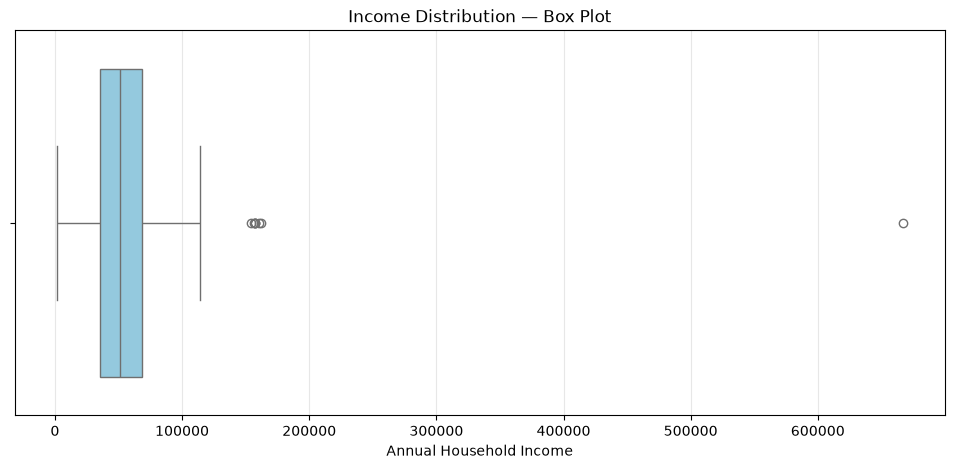

In [6]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df["Income"],
    color="skyblue"
)

plt.title("Income Distribution — Box Plot")
plt.xlabel("Annual Household Income")
plt.grid(axis="x", alpha=0.3)

plt.show()

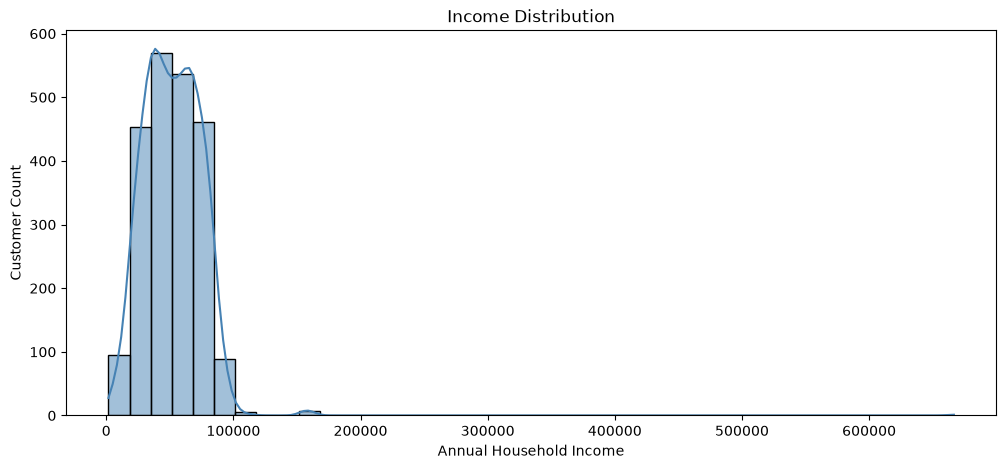

In [7]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["Income"].dropna(),
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Income Distribution")
plt.xlabel("Annual Household Income")
plt.ylabel("Customer Count")

plt.show()

In [9]:
upper_cap = df["Income"].quantile(0.99)

df["Income_Capped"] = df["Income"].clip(
    upper=upper_cap
)

print("Upper Cap:", upper_cap)

display(
    df[
        ["ID", "Income", "Income_Capped"]
    ].sort_values(
        "Income",
        ascending=False
    ).head(10)
)

Upper Cap: 94458.79999999999


,ID,Income,Income_Capped
527,9432,666666.0,94458.8
731,1503,162397.0,94458.8
497,1501,160803.0,94458.8
853,5336,157733.0,94458.8
2204,8475,157243.0,94458.8
325,4931,157146.0,94458.8
1925,11181,156924.0,94458.8
1826,5555,153924.0,94458.8
210,4619,113734.0,94458.8
832,4611,105471.0,94458.8


In [10]:
income_comparison = pd.DataFrame({
    "Metric": [
        "Mean",
        "Median",
        "Standard Deviation",
        "Maximum"
    ],
    "Original_Income": [
        df["Income"].mean(),
        df["Income"].median(),
        df["Income"].std(),
        df["Income"].max()
    ],
    "Capped_Income": [
        df["Income_Capped"].mean(),
        df["Income_Capped"].median(),
        df["Income_Capped"].std(),
        df["Income_Capped"].max()
    ]
})

display(income_comparison.round(2))

,Metric,Original_Income,Capped_Income
0,Mean,52247.25,51755.91
1,Median,51381.50,51381.50
2,Standard Deviation,25173.08,20760.60
3,Maximum,666666.00,94458.80


In [11]:
print("Minimum Birth Year:", df["Year_Birth"].min())
print("Maximum Birth Year:", df["Year_Birth"].max())

display(
    df[
        ["ID", "Year_Birth"]
    ].sort_values("Year_Birth").head(10)
)

Minimum Birth Year: 1893
Maximum Birth Year: 1996


,ID,Year_Birth
513,11004,1893
827,1150,1899
2233,7829,1900
2171,6663,1940
1740,6932,1941
1209,8800,1943
1350,1453,1943
1202,4994,1943
1475,6142,1943
1644,7106,1943


In [12]:
outlier_log = pd.DataFrame([{
    "Step": 6,
    "Column": "Income",
    "Issue": "Potential Outliers",
    "Action": "Outliers retained; capped column created",
    "Method": "IQR, Z-Score, 99th Percentile",
    "Status": "Completed"
}])

display(outlier_log)

,Step,Column,Issue,Action,Method,Status
0,6,Income,Potential Outliers,Outliers retained; capped column created,"IQR, Z-Score, 99th Percentile",Completed
